# 05 — Calcul du Modèle AHP et Score de Risque d'Inondation
## Projet GeoAI — Grand Casablanca (SCR EPSG:26191)
**Auteurs :** Siham Bouzagrar & Khawla Kadiri  
**Conforme au MCD :** `docs/schema_conceptuel_inondation.drawio`  
**Données d'entrée :** `input/mailles_100m_normalisees.csv` (2 020 705 mailles)

## 1. Imports et Chemins

In [2]:
pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if ROOT.name == 'scripts':
    ROOT = ROOT.parent

DOSSIER_SCORES = ROOT / 'donnees_traitees' / 'scores'
FICHIER_SCORE_PARQUET = DOSSIER_SCORES / 'score_risque_100m.parquet'
FICHIER_METADATA_AHP = DOSSIER_SCORES / 'calcul_ahp_metadonnees.json'
FICHIER_PRIORITE_COMMUNES = DOSSIER_SCORES / 'priorite_communes.csv'
FICHIER_CLUSTERING = DOSSIER_SCORES / 'entrees_clustering_100m.parquet'


## 2. Validation de la Cohérence AHP de Saaty (CR < 0.10)

In [4]:
with open(FICHIER_METADATA_AHP, 'r', encoding='utf-8') as f:
    meta = json.load(f)

print(f"Scénario          : {meta['scenario']}")
print(f"Date du calcul    : {meta['date_calcul']}")
print(f"Lambda max (λmax) : {meta['lambda_max']:.4f}")
print(f"Indice (CI)       : {meta['indice_coherence']:.4f}")
print(f"Ratio (CR)        : {meta['ratio_coherence']:.4f} ({meta['ratio_coherence']*100:.2f}%) < 10% [ACCEPTÉ]")

df_criteres = pd.DataFrame(meta['criteres'])
df_criteres[['variable', 'dimension', 'sens', 'poids', 'poids_ml_sqrt']]


Scénario          : baseline
Date du calcul    : 2026-11-18T17:14:33.270835
Lambda max (λmax) : 12.1430
Indice (CI)       : 0.0130
Ratio (CR)        : 0.0084 (0.84%) < 10% [ACCEPTÉ]


,variable,dimension,sens,poids,poids_ml_sqrt
0,hand_moy,Alea,cout,0.154803,0.393450
1,pente_moy,Alea,cout,0.118811,0.344690
2,depression_moy,Alea,benefice,0.078325,0.279866
3,distance_oued,Alea,cout,0.069086,0.262843
4,twi_moy,Alea,benefice,0.041766,0.204368
5,flux_max_log,Alea,benefice,0.036942,0.192204
6,ruissel_moy,Alea,benefice,0.036305,0.190539
7,indice_equip,Enjeux,benefice,0.131293,0.362344
8,densite_bati,Enjeux,benefice,0.105558,0.324897
9,densite_routes,Enjeux,benefice,0.060082,0.245117


## 3. Visualisation des Poids AHP par Critère

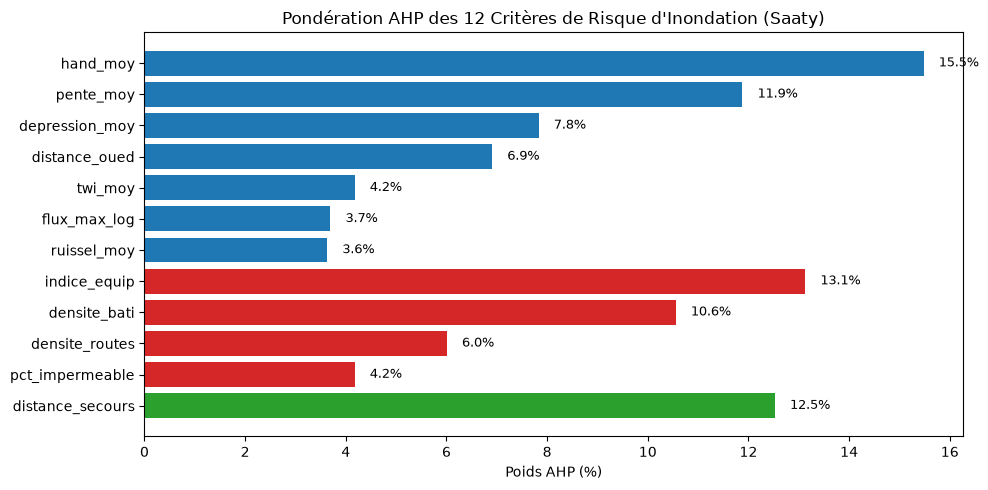

In [5]:
plt.figure(figsize=(10, 5))
colors = {'Alea': '#1f77b4', 'Enjeux': '#d62728', 'Secours': '#2ca02c'}
palette = [colors[d] for d in df_criteres['dimension']]

bars = plt.barh(df_criteres['variable'], df_criteres['poids'] * 100, color=palette)
plt.xlabel('Poids AHP (%)')
plt.title("Pondération AHP des 12 Critères de Risque d'Inondation (Saaty)")
plt.gca().invert_yaxis()
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()


## 4. Distribution Statistique du Score de Risque

Statistiques descriptives du Score de Risque :
count    2.020705e+06
mean     3.858195e-01
std      4.670944e-02
min      1.549564e-01
20%      3.477854e-01
40%      3.686022e-01
60%      3.927504e-01
80%      4.256970e-01
95%      4.710309e-01
99%      4.957476e-01
max      6.271461e-01
Name: score_risque, dtype: float64


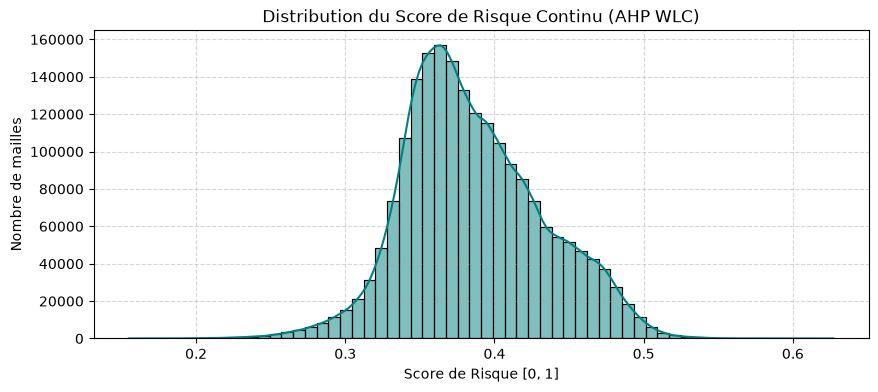

In [6]:
df_score = pd.read_parquet(FICHIER_SCORE_PARQUET)
print("Statistiques descriptives du Score de Risque :")
print(df_score['score_risque'].describe(percentiles=[0.2, 0.4, 0.6, 0.8, 0.95, 0.99]))

plt.figure(figsize=(10, 4))
sns.histplot(df_score['score_risque'], bins=60, kde=True, color='teal')
plt.title('Distribution du Score de Risque Continu (AHP WLC)')
plt.xlabel('Score de Risque [0, 1]')
plt.ylabel('Nombre de mailles')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


## 5. Synthèse des Priorités par Commune (Top 15)

In [8]:
df_prio = pd.read_csv(FICHIER_PRIORITE_COMMUNES)
df_prio[['rang_priorite', 'nom', 'score_moyen', 'score_max', 'pct_zones_elevees', 'bati_expose_m2']].head(15)


,rang_priorite,nom,score_moyen,score_max,pct_zones_elevees,bati_expose_m2
0,1,Kridid كرديد,0.484196,0.588408,0.000000,0.00
1,2,Oulad Amrane أولاد عمران,0.483172,0.554505,0.000000,0.00
2,3,Koudiat Bni Dghough كدية بني دغوغ,0.481764,0.569804,0.000000,0.00
3,4,Sidi Bennour ⵙⵉⴷⵉ ⴱⵏⵏⵓⵕ سيدي بنور,0.476421,0.606967,0.001883,18518.84
4,5,Laatatra لعطاطرة,0.476013,0.560912,0.000000,0.00
5,6,Bouhmame بوحمام,0.470702,0.574825,0.000000,0.00
6,7,Oulad Si Bouhya أولاد سي بوحيى,0.468466,0.556359,0.000000,0.00
7,8,Metrane مطران,0.467794,0.567472,0.000000,0.00
8,9,Jabria جابرية,0.467395,0.537165,0.000000,0.00
9,10,M'Tal امطل,0.464253,0.559553,0.000000,0.00


## 6. Contrôle des Entrées pour le Clustering IA (K-Means / GMM)
Conforme au MCD : `entrées = variables normalisées × √poids`

In [9]:
df_clust = pd.read_parquet(FICHIER_CLUSTERING)
print('Dimensions des entrées ML :', df_clust.shape)
df_clust.head()


Dimensions des entrées ML : (2020705, 13)


,id,hand_moy,pente_moy,depression_moy,distance_oued,twi_moy,flux_max_log,ruissel_moy,indice_equip,densite_bati,densite_routes,pct_impermeable,distance_secours
0,2,0.385231,0.330869,0.000131,0.262816,0.055234,0.033673,0.0,0.0,0.0,0.0,0.0,0.195207
1,6,0.385231,0.330869,0.000131,0.262545,0.055234,0.033673,0.0,0.0,0.0,0.0,0.0,0.195053
2,7,0.385231,0.330869,0.000131,0.262216,0.055234,0.033673,0.0,0.0,0.0,0.0,0.0,0.195068
3,8,0.385231,0.330869,0.000131,0.261886,0.055234,0.033673,0.0,0.0,0.0,0.0,0.0,0.195083
4,10,0.385231,0.330869,0.000131,0.262643,0.055234,0.033673,0.0,0.0,0.0,0.0,0.0,0.194884
